# Daily Relative Change Signal Analysis

Instead of looking at raw prices, we look at the **daily relative change** $r(t) = \frac{p(t) - p(t-1)}{p(t-1)}$. This is a dimensionless return signal that strips out the absolute price level, making stocks directly comparable regardless of share price.

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
from matplotlib import pyplot as plt
from astropy import units as u

from freqandsee.freqandsee import (
    StockSignal,
    Signal,
    SignalBundle,
    MovingAverageFilter,
    AllanFilter,
    FilterBank,
)

## Fetch prices and compute daily relative changes

In [2]:
tickers = ["AAPL", "MSFT", "GOOGL", "SHIP", "VTI", "KKR"]
stocks = {t: StockSignal(t, column="Close", period="2y") for t in tickers}

def daily_relative_change(s):
    """Compute daily relative change: r(t) = (p(t) - p(t-1)) / p(t-1)."""
    returns = np.diff(s.y.value) / s.y.value[:-1]
    return Signal(
        x=s.x[1:],
        y=returns * u.dimensionless_unscaled,
        name=f"{s.ticker} daily return",
        x_name=s.x_name,
        y_name=r"$r$",
    )

changes = {t: daily_relative_change(s) for t, s in stocks.items()}

for t, dc in changes.items():
    print(f"{t:6s}  mean={dc.mean:.4f}  std={dc.std:.4f}  n={dc.n}")

AAPL    mean=0.0006  std=0.0134  n=727
MSFT    mean=-0.0001  std=0.0118  n=727
GOOGL   mean=0.0009  std=0.0142  n=727
SHIP    mean=0.0009  std=0.0207  n=727
VTI     mean=0.0003  std=0.0081  n=727
KKR     mean=0.0001  std=0.0200  n=727


## Daily return time series

(<Figure size 1200x1000 with 6 Axes>,
 <Axes: title={'center': 'KKR daily return'}, xlabel='Days since 2024-04-01', ylabel='$r$'>)

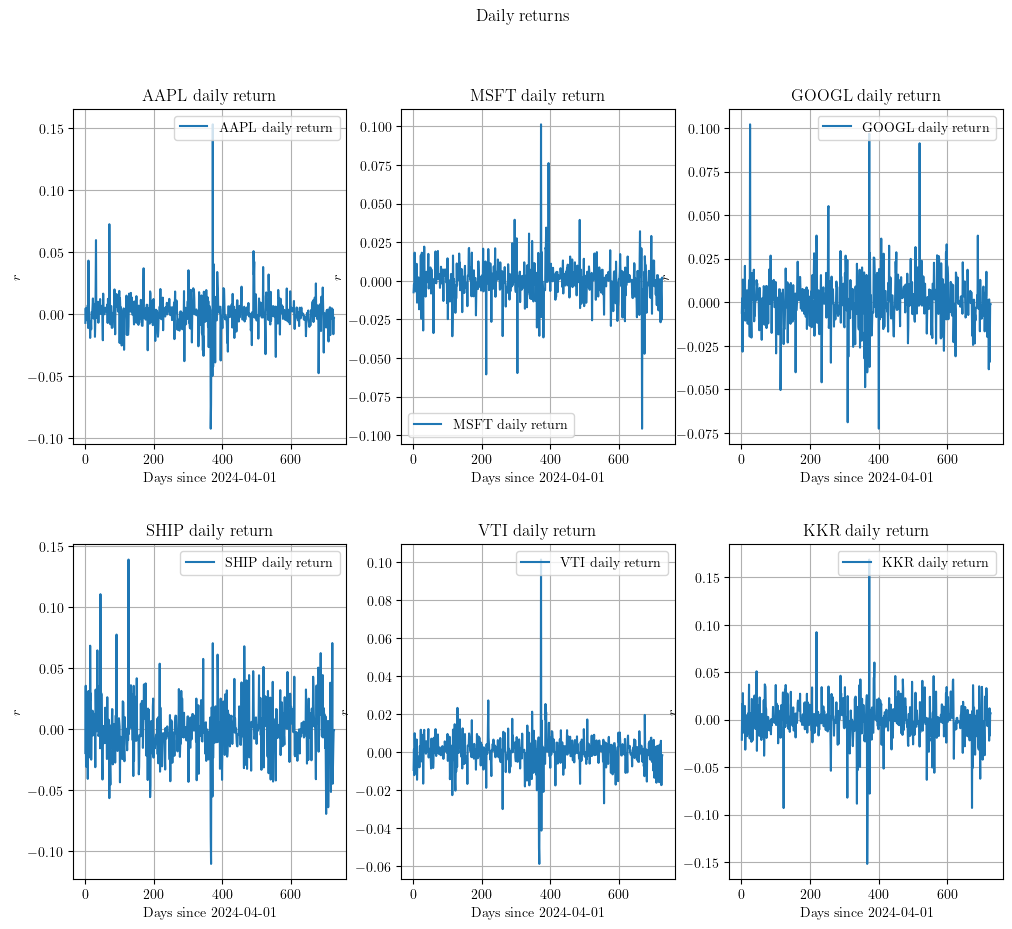

In [3]:
bundle = SignalBundle(
    [changes[t] for t in tickers],
    name="Daily returns",
)
bundle.plot(
    all_in_one=False,
    x_display_unit=u.day,
    y_display_unit=u.dimensionless_unscaled,
)

## Distribution of daily returns

If prices follow a geometric random walk, daily returns should be approximately Gaussian.

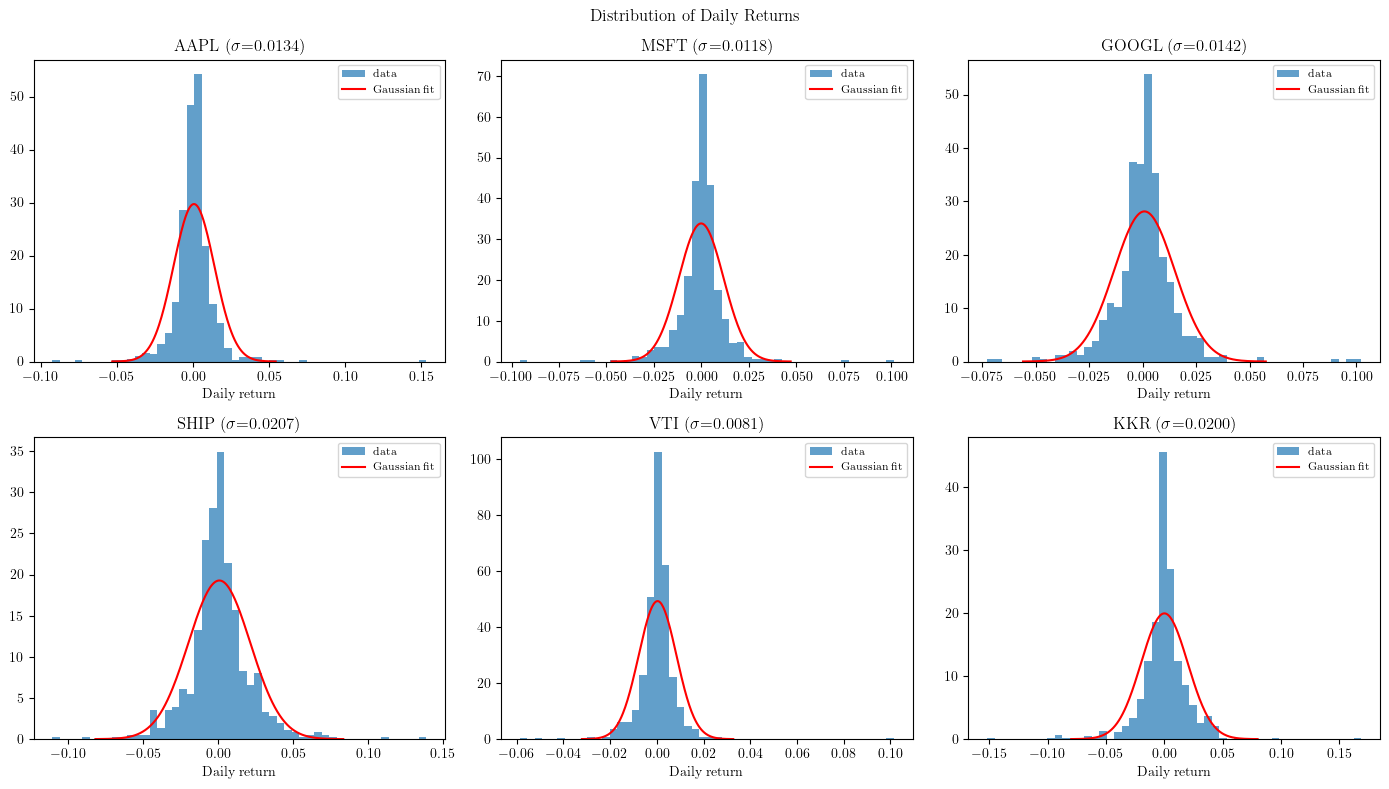

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for ax, t in zip(axes, tickers):
    dc = changes[t]
    vals = dc.y.value
    ax.hist(vals, bins=50, density=True, alpha=0.7, label="data")

    # Gaussian reference
    mu, sigma = np.mean(vals), np.std(vals)
    x_range = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 200)
    gaussian = np.exp(-0.5 * ((x_range - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))
    ax.plot(x_range, gaussian, "r-", lw=1.5, label="Gaussian fit")

    ax.set_title(f"{t} ($\\sigma$={sigma:.4f})")
    ax.set_xlabel("Daily return")
    ax.legend(fontsize=8)

fig.suptitle("Distribution of Daily Returns")
plt.tight_layout()

## Power Spectral Density of daily returns

The PSD reveals the frequency content of the return signal. White noise would appear flat; correlated returns show spectral shape.

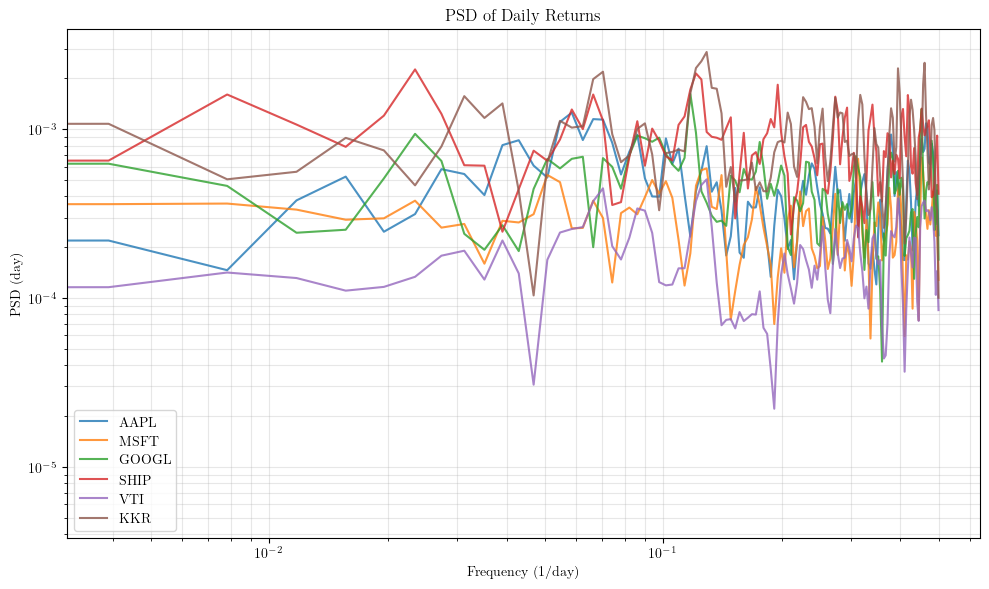

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))

for t in tickers:
    psd = changes[t].psd()
    ax.loglog(psd.x.value, psd.y.value, label=t, alpha=0.8)

ax.set_xlabel("Frequency (1/day)")
ax.set_ylabel("PSD (day)")
ax.set_title("PSD of Daily Returns")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

## Smoothed daily returns

Apply a moving average to the return signal to see if there are persistent trends.

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'AAPL daily return'}, xlabel='x(AAPL daily return * 30-day MA) ($\\mathrm{d}$)', ylabel='y(AAPL daily return * 30-day MA) $\\mathrm{}$'>)

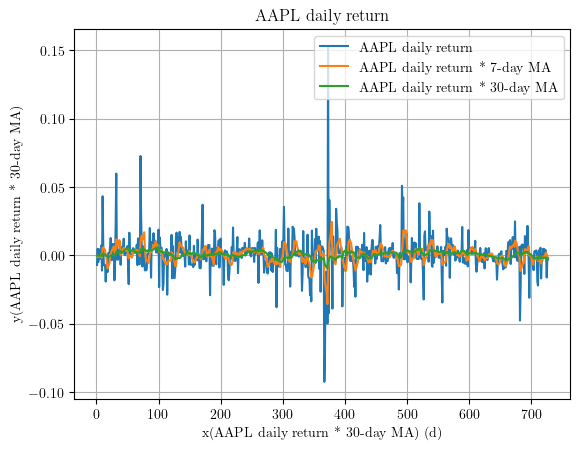

In [6]:
ticker = "AAPL"
dc = changes[ticker]

ma7 = dc * MovingAverageFilter(n=7, name="7-day MA")
ma30 = dc * MovingAverageFilter(n=30, name="30-day MA")

bundle = SignalBundle([dc, ma7, ma30], name=f"{ticker} daily return")
bundle.plot(
    all_in_one=True,
    x_display_unit=u.day,
    y_display_unit=u.dimensionless_unscaled,
)

## Volatility comparison

Compare the standard deviation of daily returns across all stocks. Since returns are already normalized by price, this is a direct apples-to-apples volatility comparison.

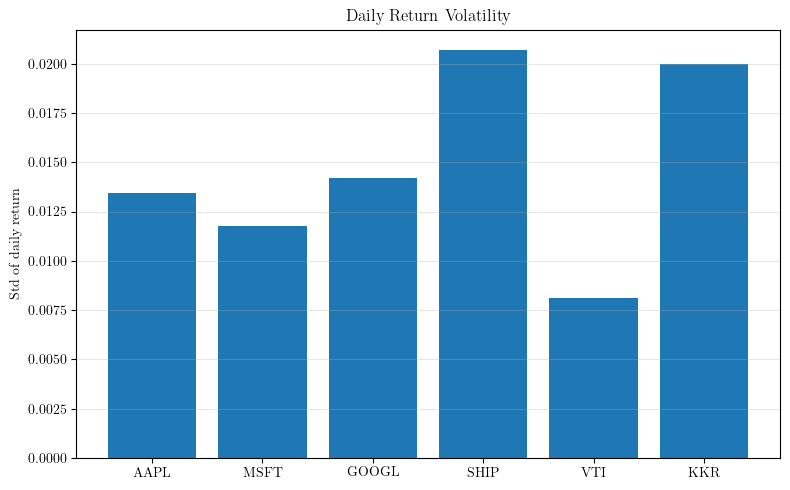

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

stds = [changes[t].std.value for t in tickers]

ax.bar(tickers, stds)
ax.set_ylabel("Std of daily return")
ax.set_title("Daily Return Volatility")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

## Allan variance of daily returns

The Allan variance on the return signal characterizes how return volatility behaves across timescales. Since returns are already dimensionless and price-normalized, all stocks are directly comparable.

- Slope $-1$ → white noise returns (independent daily fluctuations, consistent with efficient markets)
- Slope $0$ → flicker noise (volatility clustering)
- Slope $+1$ → drift in returns

In [8]:
max_exponent = 7  # 2^7 = 128 days
n_values = [2**k for k in range(1, max_exponent + 1)]
tau_days = np.array(n_values)

filter_bank = FilterBank(
    filters=[AllanFilter(n=n) for n in n_values],
    name="Allan filter bank",
)

def compute_allan_dev(signal, filter_bank):
    bundle = signal * filter_bank
    return np.array([s.rms.value for s in bundle])

adevs = {t: compute_allan_dev(changes[t], filter_bank) for t in tickers}

### Allan deviation (absolute)

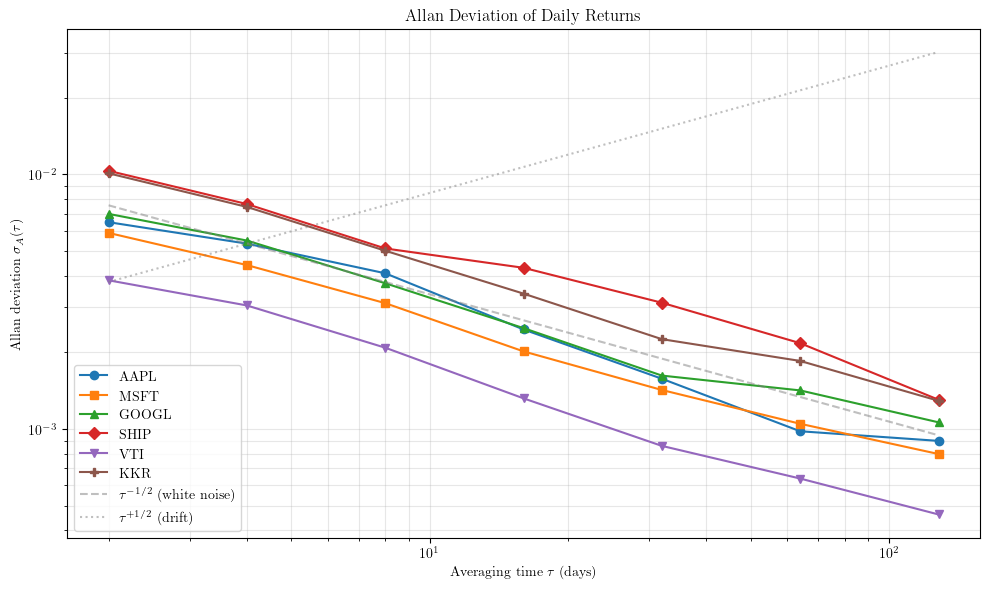

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))

markers = ["o", "s", "^", "D", "v", "P"]
for (t, adev), marker in zip(adevs.items(), markers):
    ax.loglog(tau_days, adev, f"{marker}-", label=t)

# Reference slopes
anchor = list(adevs.values())[0][1]
ref_tau = np.array([2, 128])
ax.loglog(
    ref_tau, anchor * (ref_tau / 4) ** (-0.5),
    "--", color="gray", alpha=0.5, label=r"$\tau^{-1/2}$ (white noise)",
)
ax.loglog(
    ref_tau, anchor * (ref_tau / 4) ** (0.5),
    ":", color="gray", alpha=0.5, label=r"$\tau^{+1/2}$ (drift)",
)

ax.set_xlabel(r"Averaging time $\tau$ (days)")
ax.set_ylabel(r"Allan deviation $\sigma_A(\tau)$")
ax.set_title("Allan Deviation of Daily Returns")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

### Allan-filtered daily changes at different timescales

Visualize the Allan filter output on AAPL daily changes at short, medium, and long averaging windows.

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'AAPL daily return, Allan-filtered'}, xlabel='x(AAPL daily return * 64-day) ($\\mathrm{d}$)', ylabel='y(AAPL daily return * 64-day) $\\mathrm{}$'>)

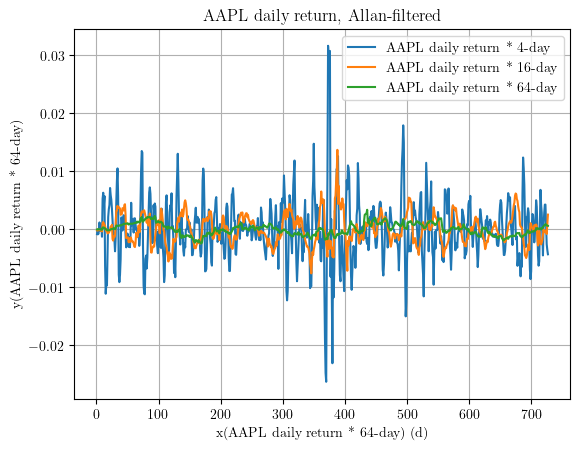

In [10]:
dc_aapl = changes["AAPL"]

short = dc_aapl * AllanFilter(n=4, name="4-day")
medium = dc_aapl * AllanFilter(n=16, name="16-day")
long = dc_aapl * AllanFilter(n=64, name="64-day")

bundle = SignalBundle([short, medium, long], name="AAPL daily return, Allan-filtered")
bundle.plot(
    all_in_one=True,
    x_display_unit=u.day,
    y_display_unit=u.dimensionless_unscaled,
)